In [59]:
print("Train scaled shape:", X_train_scaled.shape)
print("Validation scaled shape:", X_val_scaled.shape)
print("Test scaled shape:", X_test_scaled.shape)

print("\nTrain mean:")
print(X_train_scaled.mean(axis=0)[:5])

print("\nTrain std:")
print(X_train_scaled.std(axis=0)[:5])

Train scaled shape: (226980, 31)
Validation scaled shape: (28373, 31)
Test scaled shape: (28373, 31)

Train mean:
[-1.51887979e-16  1.62781841e-18 -1.22086381e-17  8.17039625e-18
 -2.65772660e-17]

Train std:
[1. 1. 1. 1. 1.]


In [61]:
import joblib

joblib.dump(scaler, "fraud_scaler.pkl")

joblib.dump(
    {
        "X_train": X_train_scaled,
        "X_val": X_val_scaled,
        "X_test": X_test_scaled,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test
    },
    "fraud_splits.pkl"
)

print("Saved successfully.")

Saved successfully.


In [62]:
from sklearn.linear_model import LogisticRegression

baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(X_train_scaled, y_train)

print("Baseline model trained.")

Baseline model trained.


Why Logistic Regression?

Conceptually:

$$ P(Fraud|X) = \sigma(w^TX+b) $$

It learns a weighted combination of the transaction features and outputs a probability of fraud.

This gives us a very important baseline:

Features
   ↓
Linear decision boundary
   ↓
Fraud probability

Later we'll compare this against nonlinear models.

In [63]:
y_val_pred = baseline_model.predict(X_val_scaled)

In [64]:
y_val_proba = baseline_model.predict_proba(X_val_scaled)[:, 1]

In [65]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, digits=4))

Confusion Matrix:
[[28321     4]
 [   22    26]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9992    0.9999    0.9995     28325
           1     0.8667    0.5417    0.6667        48

    accuracy                         0.9991     28373
   macro avg     0.9329    0.7708    0.8331     28373
weighted avg     0.9990    0.9991    0.9990     28373



In [66]:
precision = precision_score(y_val, y_val_pred)
recall = recall_score(y_val, y_val_pred)
f1 = f1_score(y_val, y_val_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)

Precision: 0.8666666666666667
Recall: 0.5416666666666666
F1: 0.6666666666666666


In [67]:
from sklearn.metrics import roc_auc_score, average_precision_score

roc_auc = roc_auc_score(y_val, y_val_proba)
pr_auc = average_precision_score(y_val, y_val_proba)

print("ROC-AUC:", roc_auc)
print("PR-AUC / AUPRC:", pr_auc)

ROC-AUC: 0.9314724919093852
PR-AUC / AUPRC: 0.6370669816765189


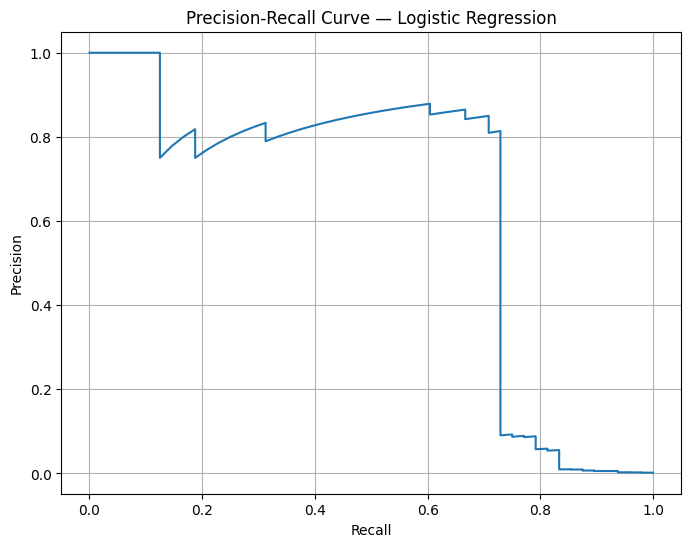

In [68]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision_curve, recall_curve, thresholds = precision_recall_curve(
    y_val,
    y_val_proba
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Logistic Regression")
plt.grid(True)

plt.show()